# 06 C++ engine vs Python reference

The Python Monte Carlo (`prs.pricing.simulate_monthly`) is the readable
reference. The C++ engine (`cpp/`, Eigen + `<random>` + `std::thread`, bound
with pybind11) implements the same model. Random numbers differ, so we
compare **distributions**, then speed.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # make src/prs importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prs.plotting import fig, use_style, label_end, BLUE, ORANGE, AQUA, GREY
use_style()
pd.set_option("display.precision", 3)

In [2]:
import os, time
from prs.pipeline import load_models
from prs.pricing import Contract, simulate_monthly, strike_terms, summary
from prs.engine import simulate_monthly_cpp
m = load_models()
c = Contract()
args = (m["wind"], m["power"], m["price"], c)
py = simulate_monthly(*args, 300, seed=0)
cpp = simulate_monthly_cpp(*args, 3000, seed=0)
rows = {}
for name, s in [("python (300 paths)", py), ("c++ (3000 paths)", cpp)]:
    rows[name] = summary(s, strike_terms(s, c), c)
pd.DataFrame(rows).round(3)

,python (300 paths),c++ (3000 paths)
fair_fixed_price_gbp_mwh,68.022,67.966
volume_weighted_baseload_gbp_mwh,76.772,76.760
capture_rate,0.886,0.885
expected_annual_volume_gwh,631.399,630.364
annual_volume_p90_gwh,575.625,574.574
annual_volume_p10_gwh,688.627,686.518
expected_capacity_factor,0.316,0.315


Text(0.0, 1.0, 'Same distributions from both engines')

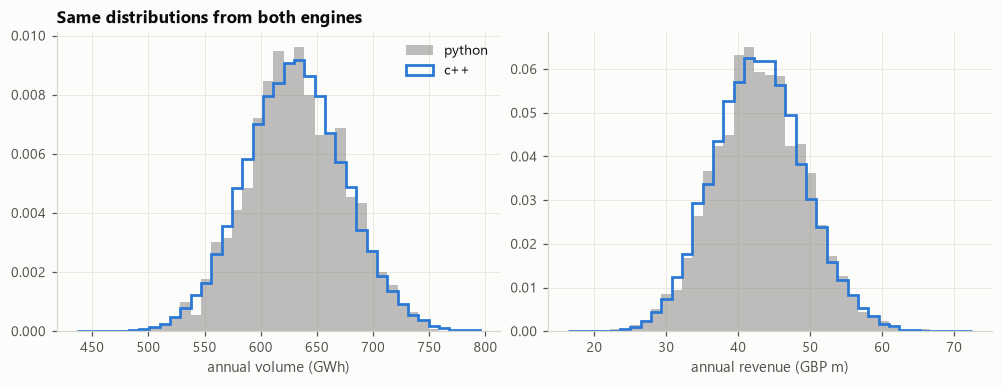

In [3]:
f, axes = fig(1, 2, figsize=(9, 3.4))
for ax, key, label in [(axes[0], "volume", "annual volume (GWh)"), (axes[1], "revenue", "annual revenue (GBP m)")]:
    scale = 1e3 if key == "volume" else 1e6
    a = py[key].reshape(-1, 10, 12).sum(2).ravel() / scale
    b = cpp[key].reshape(-1, 10, 12).sum(2).ravel() / scale
    bins = np.linspace(min(a.min(), b.min()), max(a.max(), b.max()), 40)
    ax.hist(a, bins=bins, density=True, color=GREY, alpha=0.55, lw=0, label="python")
    ax.hist(b, bins=bins, density=True, histtype="step", color=BLUE, lw=1.8, label="c++")
    ax.set_xlabel(label)
axes[0].legend(); axes[0].set_title("Same distributions from both engines")

## Speed

python reference (vectorised numpy, 1 core): 67.1 ms per 10-year hourly path


,threads,ms per path,speed-up vs python
0,1,13.14,5.11
1,2,7.66,8.76
2,4,4.18,16.04
3,8,3.15,21.30
4,16,2.69,24.94


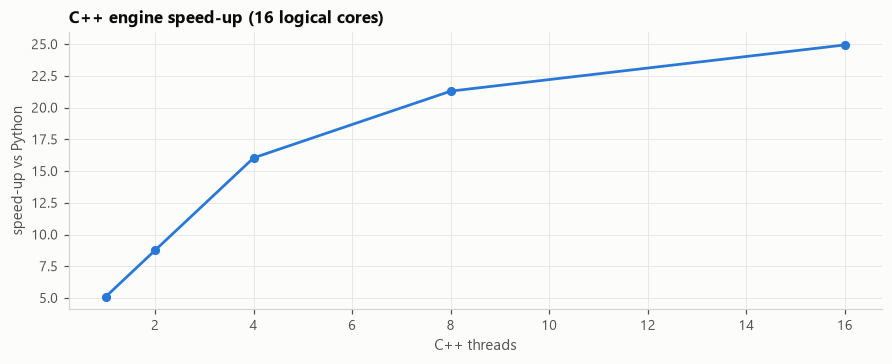

In [4]:
n = 200
t = time.time(); simulate_monthly(*args, n, seed=1); per_py = (time.time() - t) / n
threads = sorted({t for t in [1, 2, 4, 8, os.cpu_count()] if t <= os.cpu_count()})
per_cpp = []
for th in threads:
    t = time.time(); simulate_monthly_cpp(*args, 800, seed=1, n_threads=th); per_cpp.append((time.time() - t) / 800)
bench = pd.DataFrame({"threads": threads, "ms per path": np.array(per_cpp) * 1e3,
                      "speed-up vs python": per_py / np.array(per_cpp)})
print(f"python reference (vectorised numpy, 1 core): {per_py*1e3:.1f} ms per 10-year hourly path")
f, ax = fig(figsize=(8, 3.2))
ax.plot(threads, bench["speed-up vs python"], "o-", color=BLUE, ms=5)
ax.set_xlabel("C++ threads"); ax.set_ylabel("speed-up vs Python")
ax.set_title(f"C++ engine speed-up ({os.cpu_count()} logical cores)")
bench.round(2)

Each path is 87,648 hourly steps of a 24-lag bivariate VAR, two quantile
transforms, the power curve and the price process. The C++ engine is
faster even on one thread (no Python overhead per hour, no large temporary
arrays) and scales across cores because paths are independent. Each path
seeds its own generator from `(seed, path)`, so results are bit-identical
for any thread count (tested in `tests/test_engine.py`).

The pricing notebook uses 10,000 paths; at C++ speed that takes seconds,
which makes stress tests and sensitivities cheap to run.